# Exploratory Data Analysis (EDA) - Student Performance Prediction

This notebook performs exploratory data analysis on the raw synthetic dataset (`data/raw/student_data.csv`).

### 1. Load Data & Summary Statistics
Loads `data/raw/student_data.csv` using pandas and displays dataset shape, data types, and descriptive summary statistics (`df.describe()`).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set seaborn visualization style
sns.set_theme(style='whitegrid', palette='muted')

# 1. Load dataset
df = pd.read_csv('../data/raw/student_data.csv')

print('=== Dataset Shape ===')
print(f'Rows: {df.shape[0]}, Columns: {df.shape[1]}\n')

print('=== Data Types ===')
print(df.dtypes)

print('\n=== Summary Statistics ===')
display(df.describe())

=== Dataset Shape ===
Rows: 1000, Columns: 12

=== Data Types ===
study_hours           float64
attendance            float64
previous_marks        float64
assignment_score      float64
backlogs                int64
python_level              str
sql_level                 str
ml_level                  str
projects_completed      int64
study_consistency         str
practice_frequency        str
performance               str
dtype: object

=== Summary Statistics ===


,study_hours,attendance,previous_marks,assignment_score,backlogs,projects_completed
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000,1000.000000
mean,5.413500,75.351200,67.656200,64.327000,2.53600,3.913000
std,2.630701,14.608042,18.893748,20.055171,1.67974,2.577222
min,1.000000,50.200000,35.000000,30.000000,0.00000,0.000000
25%,3.100000,62.075000,51.975000,46.900000,1.00000,2.000000
50%,5.500000,75.950000,67.500000,63.900000,3.00000,4.000000
75%,7.700000,88.000000,84.325000,81.625000,4.00000,6.000000
max,10.000000,100.000000,99.900000,100.000000,5.00000,8.000000


### 2. Missing Values Check
Checks for missing or null values across all columns in the dataset using `df.isnull().sum()`.

In [2]:
# 2. Missing values check
missing_counts = df.isnull().sum()
print('=== Missing Values Count per Column ===')
print(missing_counts)

=== Missing Values Count per Column ===
study_hours           0
attendance            0
previous_marks        0
assignment_score      0
backlogs              0
python_level          0
sql_level             0
ml_level              0
projects_completed    0
study_consistency     0
practice_frequency    0
performance           0
dtype: int64


### 3. Target Class Distribution
Displays a seaborn bar chart / countplot showing the total count for each performance category (`Good`, `Average`, `Poor`).

C:\Users\Hemanth\AppData\Local\Temp\ipykernel_34020\1342484340.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x='performance', order=['Good', 'Average', 'Poor'], palette='Set2')


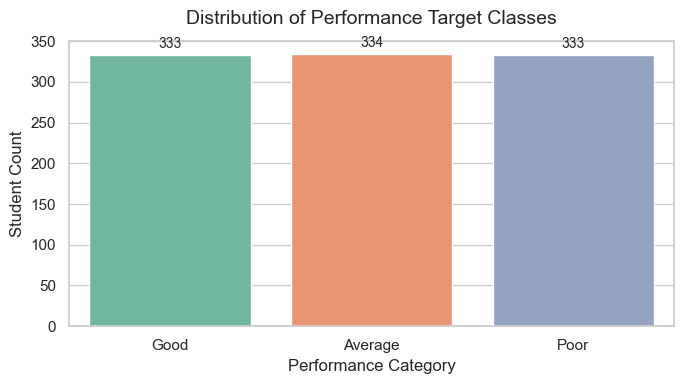

In [3]:
# 3. Performance class count bar chart
plt.figure(figsize=(7, 4))
ax = sns.countplot(data=df, x='performance', order=['Good', 'Average', 'Poor'], palette='Set2')
plt.title('Distribution of Performance Target Classes', fontsize=14, pad=12)
plt.xlabel('Performance Category', fontsize=12)
plt.ylabel('Student Count', fontsize=12)

for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'{int(height)}', (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom', fontsize=10, xytext=(0, 3), textcoords='offset points')

plt.tight_layout()
plt.show()

### 4. Correlation Heatmap (Numeric Columns)
Generates a seaborn correlation heatmap for the numerical columns (`study_hours`, `attendance`, `previous_marks`, `assignment_score`, `backlogs`, `projects_completed`).

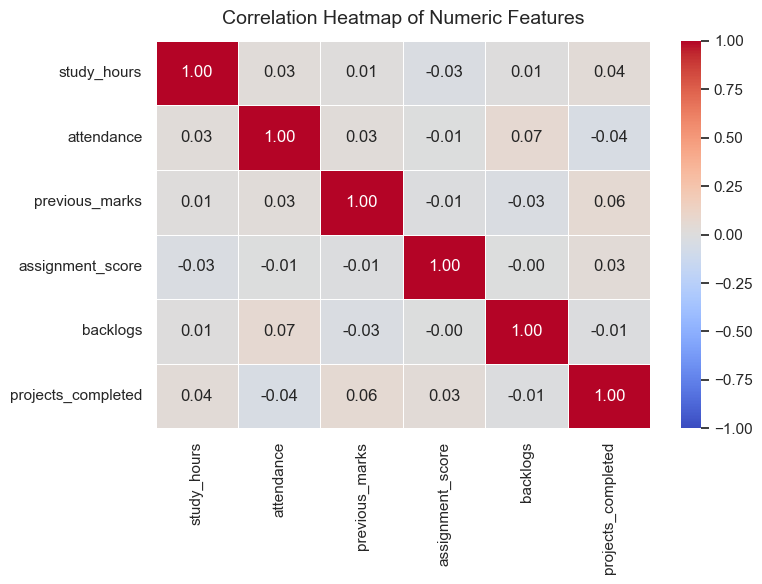

In [4]:
# 4. Correlation heatmap of numeric columns
numeric_cols = ['study_hours', 'attendance', 'previous_marks', 'assignment_score', 'backlogs', 'projects_completed']
corr = df[numeric_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Correlation Heatmap of Numeric Features', fontsize=14, pad=12)
plt.tight_layout()
plt.show()

### 5. Key Metrics Grouped by Performance Category
Displays boxplots for `study_hours`, `attendance`, and `previous_marks` grouped by performance category to visually verify feature trends.

C:\Users\Hemanth\AppData\Local\Temp\ipykernel_34020\4156695297.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='performance', y=feature, order=order, ax=axes[idx], palette='Set2')
C:\Users\Hemanth\AppData\Local\Temp\ipykernel_34020\4156695297.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='performance', y=feature, order=order, ax=axes[idx], palette='Set2')
C:\Users\Hemanth\AppData\Local\Temp\ipykernel_34020\4156695297.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='performance', y=feature, order

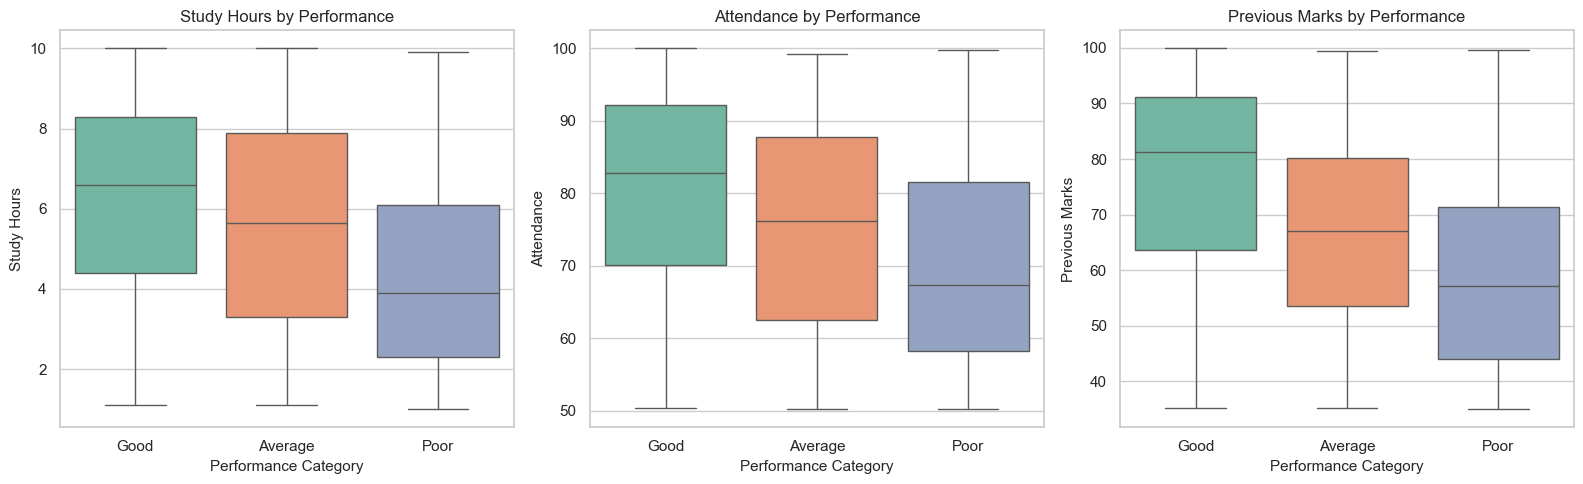

In [5]:
# 5. Boxplots of key numerical features grouped by performance
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
features = ['study_hours', 'attendance', 'previous_marks']
order = ['Good', 'Average', 'Poor']

for idx, feature in enumerate(features):
    sns.boxplot(data=df, x='performance', y=feature, order=order, ax=axes[idx], palette='Set2')
    axes[idx].set_title(f'{feature.replace("_", " ").title()} by Performance', fontsize=12)
    axes[idx].set_xlabel('Performance Category', fontsize=11)
    axes[idx].set_ylabel(feature.replace('_', ' ').title(), fontsize=11)

plt.tight_layout()
plt.show()

### 6. Study Consistency vs Performance
Displays a seaborn countplot showing `study_consistency` levels grouped by performance outcome.

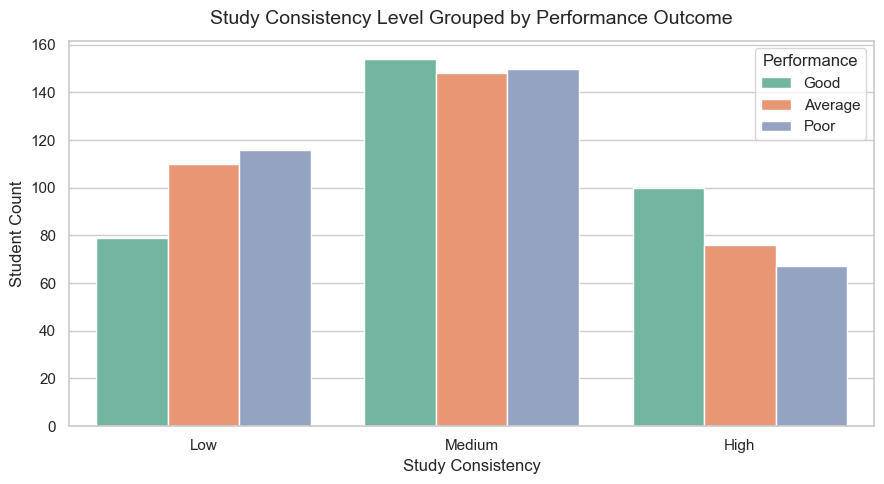

In [6]:
# 6. Countplot of study consistency grouped by performance
plt.figure(figsize=(9, 5))
sns.countplot(
    data=df,
    x='study_consistency',
    hue='performance',
    order=['Low', 'Medium', 'High'],
    hue_order=['Good', 'Average', 'Poor'],
    palette='Set2'
)
plt.title('Study Consistency Level Grouped by Performance Outcome', fontsize=14, pad=12)
plt.xlabel('Study Consistency', fontsize=12)
plt.ylabel('Student Count', fontsize=12)
plt.legend(title='Performance', loc='upper right')
plt.tight_layout()
plt.show()